## **Customer shopping**

### Contents
1. Load data and check size
2. Drop unused columns
3. Check missing values, duplicates, and dtypes
4. Split by Gender
5. EDA — Item Purchased, Size, Category, Review Rating, Purchase Amount
6. Multivariate — correlation heatmap
7. Feature engineering — dummy variables, scaling, binning
8. Summary

In [1]:
# TODO: import pandas, numpy, matplotlib.pyplot, and seaborn
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# TODO: load shopping_trends.csv with pd.read_csv(), then show the first 5 rows
df = pd.read_csv('shopping_trends.csv')

In [3]:
# TODO: check the dataset size with df.shape
df.shape

(3900, 19)

In [7]:
# TODO: drop the Customer ID column  
df.drop('Customer ID',axis=1)

,Age,Gender,Item Purchased,Category,Purchase Amount (USD),Location,Size,Color,Season,Review Rating,Subscription Status,Payment Method,Shipping Type,Discount Applied,Promo Code Used,Previous Purchases,Preferred Payment Method,Frequency of Purchases
0,55,Male,Blouse,Clothing,53,Kentucky,L,Gray,Winter,3.1,Yes,Credit Card,Express,Yes,Yes,14,Venmo,Fortnightly
1,19,Male,Sweater,Clothing,64,Maine,L,Maroon,Winter,3.1,Yes,Bank Transfer,Express,Yes,Yes,2,Cash,Fortnightly
2,50,Male,Jeans,Clothing,73,Massachusetts,S,Maroon,Spring,3.1,Yes,Cash,Free Shipping,Yes,Yes,23,Credit Card,Weekly
3,21,Male,Sandals,Footwear,90,Rhode Island,M,Maroon,Spring,3.5,Yes,PayPal,Next Day Air,Yes,Yes,49,PayPal,Weekly
4,45,Male,Blouse,Clothing,49,Oregon,M,Turquoise,Spring,2.7,Yes,Cash,Free Shipping,Yes,Yes,31,PayPal,Annually
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3895,40,Female,Hoodie,Clothing,28,Virginia,L,Turquoise,Summer,4.2,No,Cash,2-Day Shipping,No,No,32,Venmo,Weekly
3896,52,Female,Backpack,Accessories,49,Iowa,L,White,Spring,4.5,No,PayPal,Store Pickup,No,No,41,Bank Transfer,Bi-Weekly
3897,46,Female,Belt,Accessories,33,New Jersey,L,Green,Spring,2.9,No,Credit Card,Standard,No,No,24,Venmo,Quarterly
3898,44,Female,Shoes,Footwear,77,Minnesota,S,Brown,Summer,3.8,No,PayPal,Express,No,No,24,Venmo,Weekly


### **Data quality**

Check dtypes, missing values, and duplicate rows before plotting.

In [10]:
# TODO: check columns, dtypes, and non-null counts with df.info()
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3900 entries, 0 to 3899
Data columns (total 19 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Customer ID               3900 non-null   int64  
 1   Age                       3900 non-null   int64  
 2   Gender                    3900 non-null   str    
 3   Item Purchased            3900 non-null   str    
 4   Category                  3900 non-null   str    
 5   Purchase Amount (USD)     3900 non-null   int64  
 6   Location                  3900 non-null   str    
 7   Size                      3900 non-null   str    
 8   Color                     3900 non-null   str    
 9   Season                    3900 non-null   str    
 10  Review Rating             3900 non-null   float64
 11  Subscription Status       3900 non-null   str    
 12  Payment Method            3900 non-null   str    
 13  Shipping Type             3900 non-null   str    
 14  Discount Applied   

In [11]:
# TODO: check missing values with df.isnull().sum()
df.isnull().sum()

Customer ID                 0
Age                         0
Gender                      0
Item Purchased              0
Category                    0
Purchase Amount (USD)       0
Location                    0
Size                        0
Color                       0
Season                      0
Review Rating               0
Subscription Status         0
Payment Method              0
Shipping Type               0
Discount Applied            0
Promo Code Used             0
Previous Purchases          0
Preferred Payment Method    0
Frequency of Purchases      0
dtype: int64

In [12]:
# TODO: check duplicate rows with df.duplicated().sum()
df.duplicated().sum()

np.int64(0)

In [13]:
# TODO: univariate — describe numeric columns
df.describe()

,Customer ID,Age,Purchase Amount (USD),Review Rating,Previous Purchases
count,3900.000000,3900.000000,3900.000000,3900.000000,3900.000000
mean,1950.500000,44.068462,59.764359,3.749949,25.351538
std,1125.977353,15.207589,23.685392,0.716223,14.447125
min,1.000000,18.000000,20.000000,2.500000,1.000000
25%,975.750000,31.000000,39.000000,3.100000,13.000000
50%,1950.500000,44.000000,60.000000,3.700000,25.000000
75%,2925.250000,57.000000,81.000000,4.400000,38.000000
max,3900.000000,70.000000,100.000000,5.000000,50.000000


In [17]:
# TODO: split the data into male_df and female_df using df[df['Gender']==...]
male_df = df[df['Gender']=='Female']
female_df = df[df['Gender']=='Male']

print(male_df.head())
print(female_df.head())

      Customer ID  Age  Gender Item Purchased     Category  \
2652         2653   23  Female         Shorts     Clothing   
2653         2654   67  Female         Blouse     Clothing   
2654         2655   23  Female           Coat    Outerwear   
2655         2656   26  Female     Sunglasses  Accessories   
2656         2657   52  Female         Shorts     Clothing   

      Purchase Amount (USD)   Location Size     Color  Season  Review Rating  \
2652                     20   Maryland    L      Cyan  Summer            3.3   
2653                     36  Wisconsin    L  Lavender    Fall            4.8   
2654                     70      Idaho    S      Pink    Fall            4.1   
2655                     83    Wyoming    M      Gray  Summer            3.4   
2656                     76    Indiana    L    Yellow  Winter            3.6   

     Subscription Status Payment Method   Shipping Type Discount Applied  \
2652                  No     Debit Card  2-Day Shipping               

## **EDA**

### **Item Purchased**

In [19]:
# TODO: count top items with value_counts().reset_index() for male, female, and all customers
topItem = df['Item Purchased'].value_counts().reset_index()
print(topItem)
topItem_female = female_df['Item Purchased'].value_counts().reset_index()
print(topItem_female)
topItem_male = male_df['Item Purchased'].value_counts().reset_index()
print(topItem_male)

   Item Purchased  count
0          Blouse    171
1           Pants    171
2         Jewelry    171
3           Shirt    169
4           Dress    166
5         Sweater    164
6          Jacket    163
7            Coat    161
8      Sunglasses    161
9            Belt    161
10        Sandals    160
11          Socks    159
12          Skirt    158
13         Shorts    157
14          Scarf    157
15            Hat    154
16        Handbag    153
17         Hoodie    151
18          Shoes    150
19        T-shirt    147
20       Sneakers    145
21          Boots    144
22       Backpack    143
23         Gloves    140
24          Jeans    124
   Item Purchased  count
0           Pants    123
1         Jewelry    119
2         Sweater    114
3            Coat    114
4           Dress    114
5           Scarf    112
6           Shirt    110
7          Shorts    109
8           Skirt    109
9          Jacket    109
10       Backpack    106
11           Belt    106
12         Blouse    105


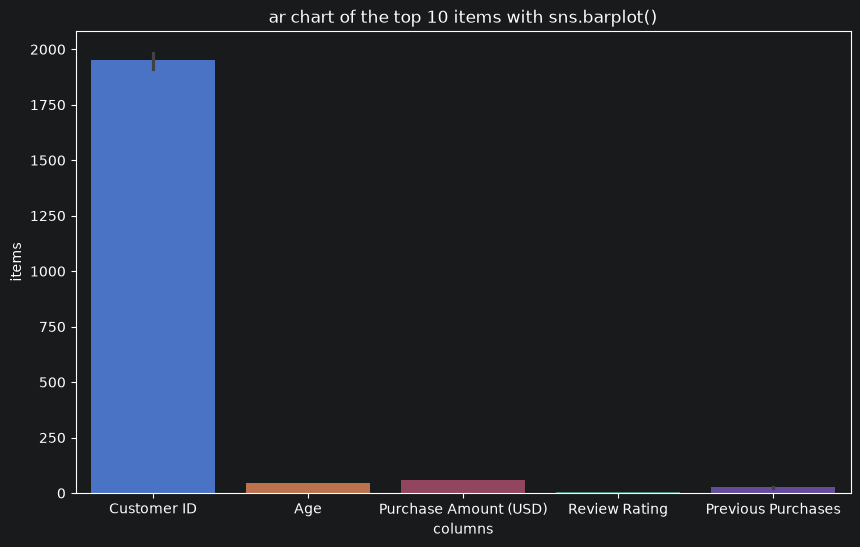

In [21]:
# TODO: plot a horizontal bar chart of the top 10 items with sns.barplot()
plt.figure(figsize=(10, 6))
sns.barplot(df,legend='auto' )
plt.title('ar chart of the top 10 items with sns.barplot()')
plt.xlabel('columns')
plt.ylabel('items')
plt.show()

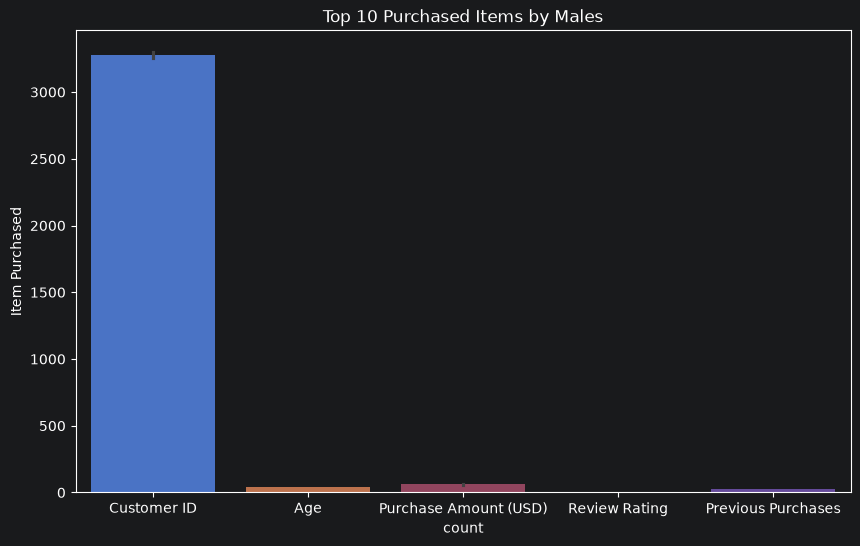

Index(['Customer ID', 'Age', 'Gender', 'Item Purchased', 'Category',
       'Purchase Amount (USD)', 'Location', 'Size', 'Color', 'Season',
       'Review Rating', 'Subscription Status', 'Payment Method',
       'Shipping Type', 'Discount Applied', 'Promo Code Used',
       'Previous Purchases', 'Preferred Payment Method',
       'Frequency of Purchases'],
      dtype='str')
   Customer ID  Age Gender Item Purchased  Category  Purchase Amount (USD)  \
0            1   55   Male         Blouse  Clothing                     53   
1            2   19   Male        Sweater  Clothing                     64   
2            3   50   Male          Jeans  Clothing                     73   
3            4   21   Male        Sandals  Footwear                     90   
4            5   45   Male         Blouse  Clothing                     49   

        Location Size      Color  Season  Review Rating Subscription Status  \
0       Kentucky    L       Gray  Winter            3.1                 Ye

In [26]:
# TODO: plot a horizontal bar chart of the top 10 items for males with sns.barplot()
plt.figure(figsize=(10, 6))
sns.barplot(male_df)
plt.title("Top 10 Purchased Items by Males")
plt.xlabel('count')
plt.ylabel('Item Purchased')
plt.show()


print(female_df.columns)
print(female_df.head())

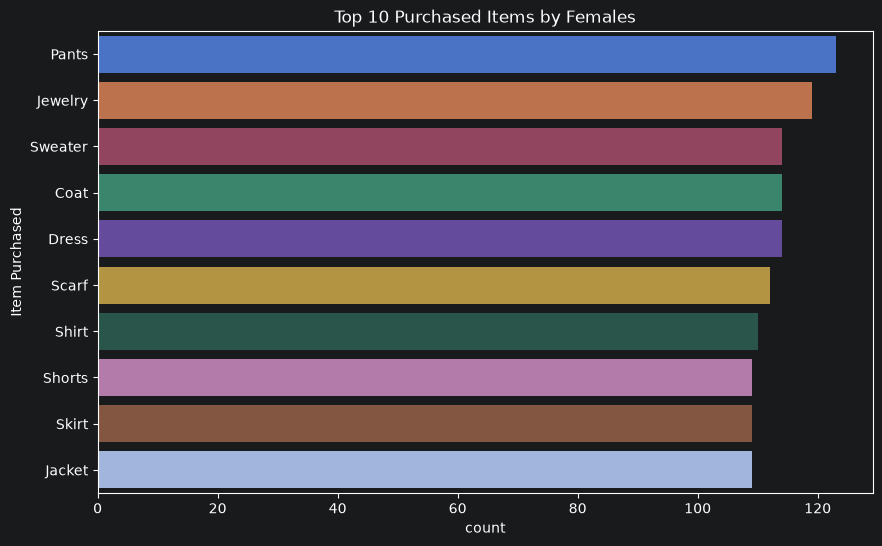

In [28]:
# TODO: plot a horizontal bar chart of the top 10 items for females with sns.barplot()
plt.figure(figsize=(10, 6))
sns.barplot(
     data=topItem_female.head(10),
     y='Item Purchased',
     x='count',
     hue='Item Purchased',
     dodge=False,
     legend=False
)
plt.title("Top 10 Purchased Items by Females")
plt.xlabel('count')
plt.ylabel('Item Purchased')
plt.show()

In [34]:
# TODO: count Size with value_counts() for all customers
count_size_customers = df['Size'].value_counts()
print(count_size_customers)

Size
M     1755
L     1053
S      663
XL     429
Name: count, dtype: int64


In [35]:
# TODO: count Size with value_counts() for male_df and female_df
print(male_df['Size'].value_counts())
print(female_df['Size'].value_counts())

Size
M     590
L     337
S     187
XL    134
Name: count, dtype: int64
Size
M     1165
L      716
S      476
XL     295
Name: count, dtype: int64


### **Category**

In [36]:
# TODO: count Category with value_counts().reset_index() for all customers
ctg = df['Category'].value_counts().reset_index()
print(ctg)

      Category  count
0     Clothing   1737
1  Accessories   1240
2     Footwear    599
3    Outerwear    324


In [45]:
# TODO: count Category with value_counts().reset_index() for male_df and female_df
ctg_male = male_df['Category'].value_counts().reset_index()
print(ctg_male)
ctg_female =female_df['Category'].value_counts().reset_index()
print(ctg)

      Category  count
0     Clothing    556
1  Accessories    392
2     Footwear    199
3    Outerwear    101
      Category  count
0     Clothing   1737
1  Accessories   1240
2     Footwear    599
3    Outerwear    324


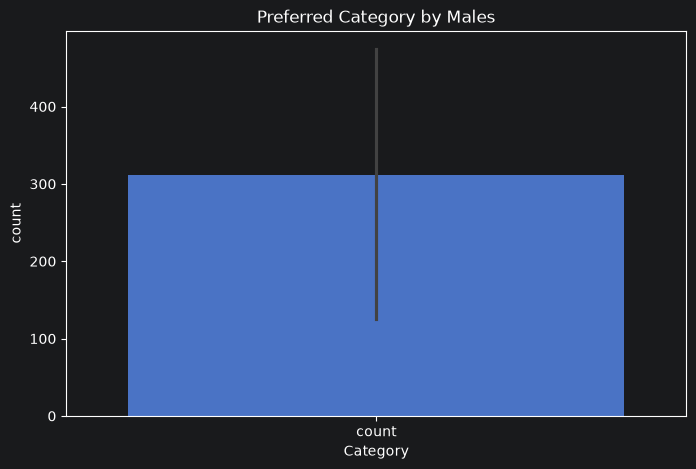

In [43]:
# TODO: plot a bar chart of preferred Category for males with sns.barplot()
plt.figure(figsize=(8, 5))
sns.barplot(ctg_male)
plt.title("Preferred Category by Males")
plt.xlabel('Category')
plt.ylabel('count')
plt.show()

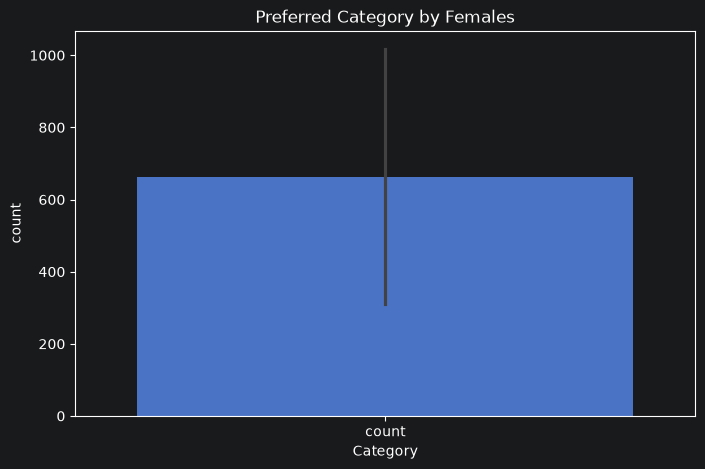

In [46]:
# TODO: plot a bar chart of preferred Category for females with sns.barplot()
plt.figure(figsize=(8, 5))
sns.barplot(ctg_female)
plt.title("Preferred Category by Females")
plt.xlabel('Category')
plt.ylabel('count')
plt.show()

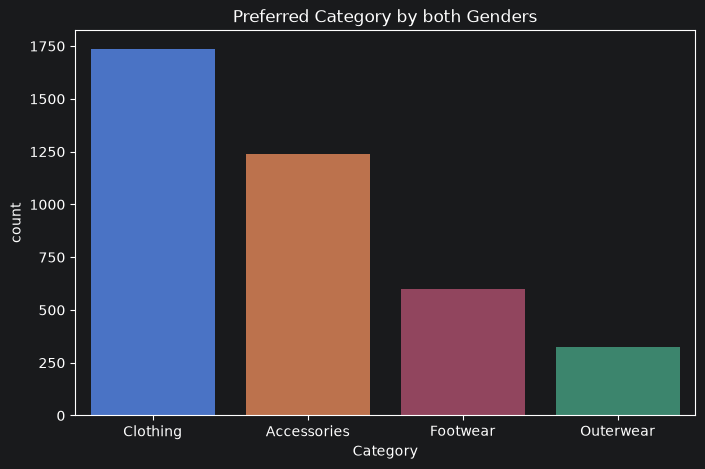

In [47]:
# TODO: plot a bar chart of preferred Category for both genders with sns.barplot()
plt.figure(figsize=(8, 5))
sns.barplot(
     data=ctg,
     x='Category',
     y='count',
     hue='Category',
     dodge=False,
     legend=False
)
plt.title("Preferred Category by both Genders")
plt.show()


In [48]:
# TODO: create waffle_data_m and waffle_data_f from Category value_counts()
waffle_data_m = dict(male_df['Category'].value_counts())
waffle_data_f = dict(female_df['Category'].value_counts())


# TODO: create waffle_data_f from female_df['Category'].value_counts()


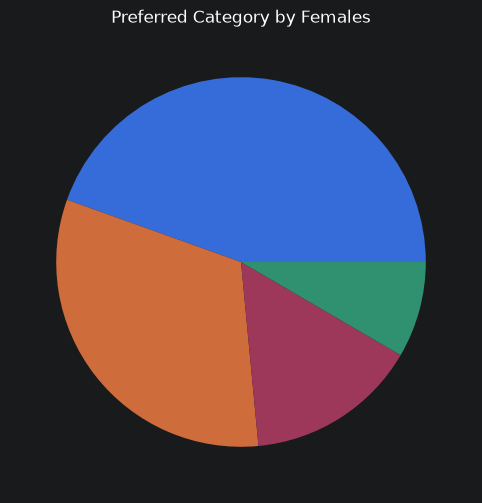

In [53]:
# TODO: plot a pie chart of preferred Category for females with plt.pie()
plt.figure(figsize=(6, 6))
plt.pie(female_df['Category'].value_counts())
plt.title("Preferred Category by Females")
plt.show()

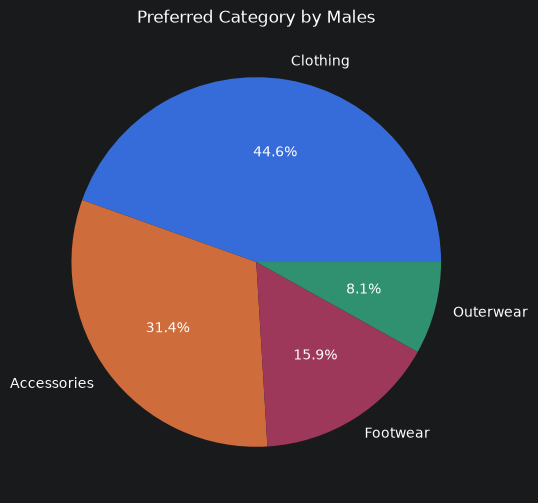

In [54]:
# TODO: plot a pie chart of preferred Category for males with plt.pie()
plt.figure(figsize=(6, 6))
plt.pie(waffle_data_m.values(),
labels=waffle_data_m.keys(),
autopct='%1.1f%%')
plt.title("Preferred Category by Males")
plt.show()

### **Review ratings**

In [59]:
# TODO: filter female Clothing rows, then mean of Review Rating
cr_f = female_df[female_df['Category']=="Clothing"]
avg_cr_f = cr_f['Review Rating'].mean()
print(avg_cr_f)

3.7319220999153258


In [61]:
# TODO: filter male Clothing rows, then mean of Review Rating
cr_m = male_df[male_df['Category']=="Clothing"]
avg_cr_m = cr_m['Review Rating'].mean()
print(avg_cr_m)

3.7044964028776977


In [ ]:
# avg_cr_m,avg_cr_f

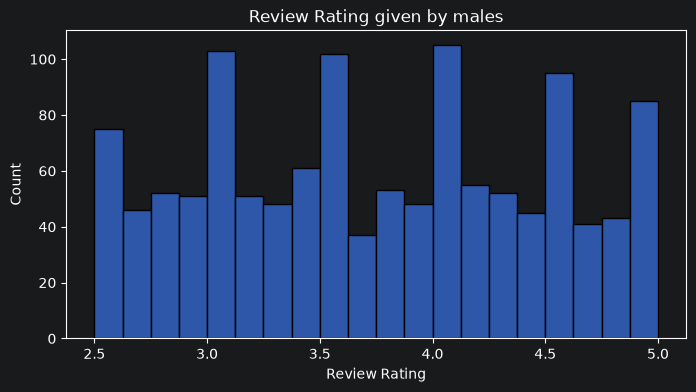

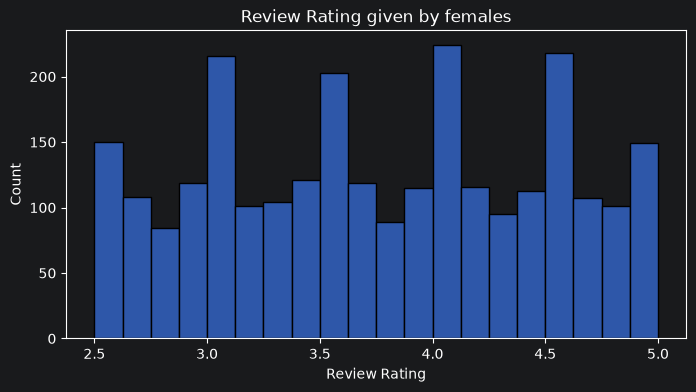

In [63]:
# TODO: plot Review Rating histograms for males and females with sns.histplot()
# males
plt.figure(figsize=(8, 4))
sns.histplot(data=male_df, x='Review Rating', bins=20)
plt.title("Review Rating given by males")
plt.show()

# females
plt.figure(figsize=(8, 4))
sns.histplot(data=female_df, x='Review Rating', bins=20)
plt.title("Review Rating given by females")
plt.show()
# ?

In [66]:
# TODO: count Review Rating with value_counts() for male Clothing (cr_m)
print(cr_m.value_counts())

count
1    556
Name: count, dtype: int64


### **Purchase Amount (USD)**

In [69]:
# TODO: sum Purchase Amount (USD) for males
m_tpa = male_df['Purchase Amount (USD)'].sum()
print(m_tpa)
# # TODO: sum Purchase Amount (USD) for females
f_tpa = female_df['Purchase Amount (USD)'].sum()
print(f_tpa)
# f_tpa =?

75191
157890


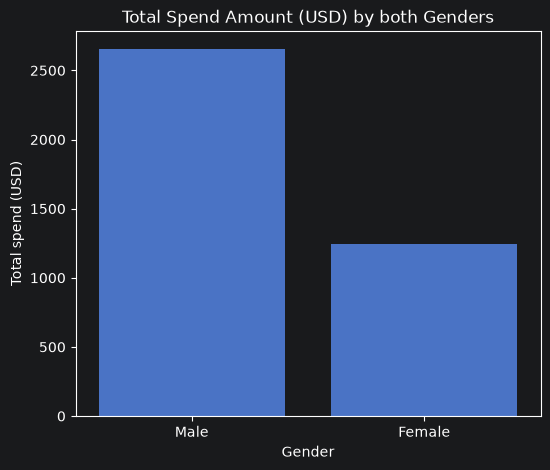

In [70]:
# TODO: plot total spend by gender with sns.barplot()
plt.figure(figsize=(6, 5))
sns.barplot(df['Gender'].value_counts())
plt.title("Total Spend Amount (USD) by both Genders")
plt.ylabel('Total spend (USD)')
plt.show()

In [71]:
# TODO: filter female_df by Category: Clothing, Accessories, Footwear, Outerwear
cc_f = cr_f
ca_f = female_df[female_df['Category']=='Accessories']
cf_f = female_df[female_df['Category']=='Footwear']
co_f = female_df[female_df['Category']=='Outerwear']

In [72]:
# TODO: filter male_df by Category: Clothing, Accessories, Footwear, Outerwear
cc_m = cr_m
ca_m = male_df[male_df['Category']=='Accessories']
cf_m =male_df[male_df['Category']=='Footwear']
co_m = male_df[male_df['Category']=='Outerwear']

In [73]:
# TODO: create pcu dict from Promo Code Used value_counts()
df['Promo Code Used'].value_counts()

Promo Code Used
No     2223
Yes    1677
Name: count, dtype: int64

### **Relationships (multivariate)**

Numeric columns only: Age, Purchase Amount (USD), Review Rating, Previous Purchases.

<Axes: >

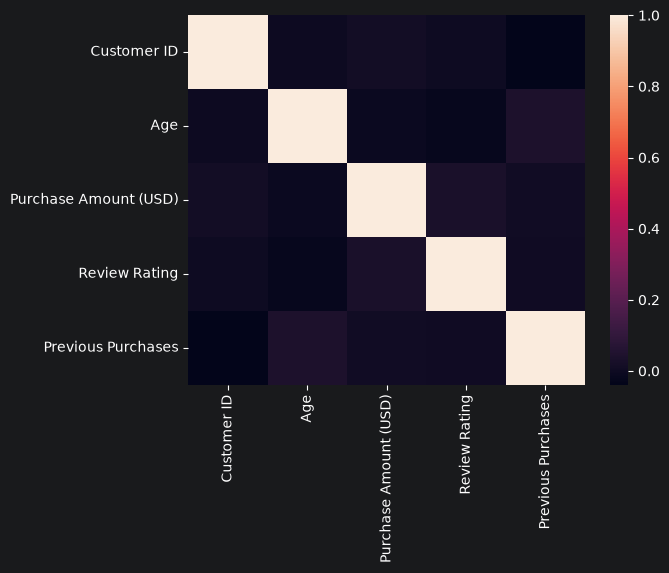

In [74]:
# TODO: compute correlation with df.corr(numeric_only=True), then plot a heatmap with sns.heatmap()

sns.heatmap(df.corr(numeric_only=True))

### **Feature engineering**

Dummy variables for columns with few levels. Scale numeric columns (keep originals). Bin purchase amount.

In [75]:
# TODO: dummy variables for Gender, Size, and Category with pd.get_dummies()
df = pd.get_dummies(df, columns=['Gender','Size','Category'], dtype=str)
df.head()

,Customer ID,Age,Item Purchased,Purchase Amount (USD),Location,Color,Season,Review Rating,Subscription Status,Payment Method,...,Gender_Female,Gender_Male,Size_L,Size_M,Size_S,Size_XL,Category_Accessories,Category_Clothing,Category_Footwear,Category_Outerwear
0,1,55,Blouse,53,Kentucky,Gray,Winter,3.1,Yes,Credit Card,...,False,True,True,False,False,False,False,True,False,False
1,2,19,Sweater,64,Maine,Maroon,Winter,3.1,Yes,Bank Transfer,...,False,True,True,False,False,False,False,True,False,False
2,3,50,Jeans,73,Massachusetts,Maroon,Spring,3.1,Yes,Cash,...,False,True,False,False,True,False,False,True,False,False
3,4,21,Sandals,90,Rhode Island,Maroon,Spring,3.5,Yes,PayPal,...,False,True,False,True,False,False,False,False,True,False
4,5,45,Blouse,49,Oregon,Turquoise,Spring,2.7,Yes,Cash,...,False,True,False,True,False,False,False,True,False,False


In [77]:
# TODO: use MinMaxScaler on Purchase Amount (USD) and StandardScaler on Age (keep original columns)
from sklearn.preprocessing import MinMaxScaler, StandardScaler

df['Amount_minmax'] = MinMaxScaler()
df['Age_standard'] = StandardScaler()
df[['Purchase Amount (USD)', 'Amount_minmax', 'Age', 'Age_standard']].head()

,Purchase Amount (USD),Amount_minmax,Age,Age_standard
0,53,MinMaxScaler(),55,StandardScaler()
1,64,MinMaxScaler(),19,StandardScaler()
2,73,MinMaxScaler(),50,StandardScaler()
3,90,MinMaxScaler(),21,StandardScaler()
4,49,MinMaxScaler(),45,StandardScaler()


In [83]:
# TODO: use pd.cut() to bin Purchase Amount (USD) into Low / Medium / High
df['Amount_bin'] =  pd.cut(df['Purchase Amount (USD)'],bins=[0, 25, 50, 75, float("inf")])
df['Amount_bin'].value_counts()

Amount_bin
(75.0, inf]     1214
(25.0, 50.0]    1209
(50.0, 75.0]    1172
(0.0, 25.0]      305
Name: count, dtype: int64

### **Summary**

Write 4–5 insights from the plots. These are associations, not causal claims.

Examples to check:
- Which items and categories are most common for males vs females?
- Do males and females spend a similar total amount?
- Is Review Rating similar across genders?
- How often is a promo code used?

# TODO: write insights
- 
- 
- 
- 

Caveat: correlation is not causation.